# 03. CNN: custom architectures and transfer learning

**Role 3.** This notebook compares custom convolutional neural networks (CNNs) trained from scratch with pretrained CNNs using transfer learning on the ASL Alphabet dataset. It uses the shared manifest split and data loader from [01_data.ipynb](01_data.ipynb); it does not create another split or change class labels.

The experiment compares simple and complex CNN architectures and investigates how data augmentation, color representation, image resolution, and the number of classes affect classification performance. The baseline configuration uses 64x64 RGB images across all 29 ASL Alphabet classes, with 54,900 training images, 9,225 validation images, and 8,875 test images.

Validation results are used for model selection, while the held-out test set is reserved for final evaluation. All models use the shared evaluation protocol to compare accuracy, macro precision, recall, F1-score, training duration, and CPU batch-one inference latency. Training and validation curves are also examined to identify overfitting and assess generalization performance.

**Notebook contents**

1. Experimental methods and CNN architectures
2. Shared evaluation and model comparison
3. Confusion analysis and limitations

In [21]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data
import evaluate

from experiment2 import make_experiments

## 1. Experimental methods and CNN architectures

All experiments use the shared ASL Alphabet dataset, fixed manifest splits, and random seed of 42. The baseline configuration uses 64 × 64 RGB images across all 29 classes.

Three CNN architectures are evaluated:

- **Simple CNN:** Two convolutional layers with max pooling and fully connected classification layers.
- **Complex CNN:** Three convolutional layers with batch normalization, max pooling, global average pooling, and dropout.
- **Pretrained CNN:** MobileNetV2 with pretrained ImageNet weights, a frozen feature extraction backbone, and a custom classification head.

Additional experiments investigate the effects of data augmentation, grayscale images, reduced image resolution, and a reduced set of 10 classes.

In [22]:
manifest = data.load_manifest()

manifest["split"].value_counts()

split
train     54900
buffer    14000
val        9225
test       8875
Name: count, dtype: int64

In [23]:
experiments = pd.DataFrame(make_experiments()).T

experiments

,model,size,color,subset,augmentation
simple_cnn_rgb64,simple_cnn,64,True,None,False
complex_cnn_rgb64,complex_cnn,64,True,None,False
complex_cnn_augmented,complex_cnn,64,True,None,True
complex_cnn_grayscale,complex_cnn,64,False,None,False
complex_cnn_rgb32,complex_cnn,32,True,None,False
complex_cnn_10class,complex_cnn,64,True,10class,False
pretrained_cnn_rgb64,pretrained_cnn,64,True,None,False


### Reproduction

The CNN architectures and prediction wrapper are implemented in `cnn_model.py`. Training, evaluation, and result generation are implemented in `experiment2.py`.

To reproduce all experiments in a separate results directory:

`python experiment2.py --results-dir results/experiment2_rerun`

Individual experiments can be executed using the `--experiment` argument.

This notebook loads saved experimental results rather than retraining the models.

## 2. Shared evaluation and model comparison

All models are evaluated using the shared evaluation protocol implemented in `evaluate.py`. The reported metrics include accuracy, macro precision, macro recall, macro F1-score, training duration, and CPU batch-one inference latency.

Validation performance is used for model selection, while the held-out test set is used for final evaluation.

In [24]:
results_dir = Path("results/experiment2")

comparison = pd.read_csv(results_dir / "comparison.csv")

comparison[
    [
        "data_variant",
        "n_train",
        "num_classes",
        "val_accuracy",
        "test_accuracy",
        "test_macro_precision",
        "test_macro_recall",
        "test_macro_f1",
        "train_time_s"
    ]
].round(4)

,data_variant,n_train,num_classes,val_accuracy,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,train_time_s
0,simple_cnn_rgb64,54900,29,0.6202,0.6122,0.6254,0.6123,0.6086,704.6976
1,complex_cnn_rgb64,54900,29,0.8889,0.8678,0.8766,0.8703,0.8654,1704.2105
2,complex_cnn_augmented,109800,29,0.8546,0.8551,0.8755,0.8542,0.8536,3287.6913
3,complex_cnn_grayscale,54900,29,0.8018,0.7850,0.8595,0.7866,0.7961,1870.1513
4,complex_cnn_rgb32,54900,29,0.8531,0.8455,0.8567,0.8446,0.8440,516.1221
5,complex_cnn_10class,18875,10,0.4611,0.3839,0.5553,0.3903,0.3547,607.6962
6,pretrained_cnn_rgb64,54900,29,0.6345,0.6587,0.6677,0.6593,0.6573,1520.5612


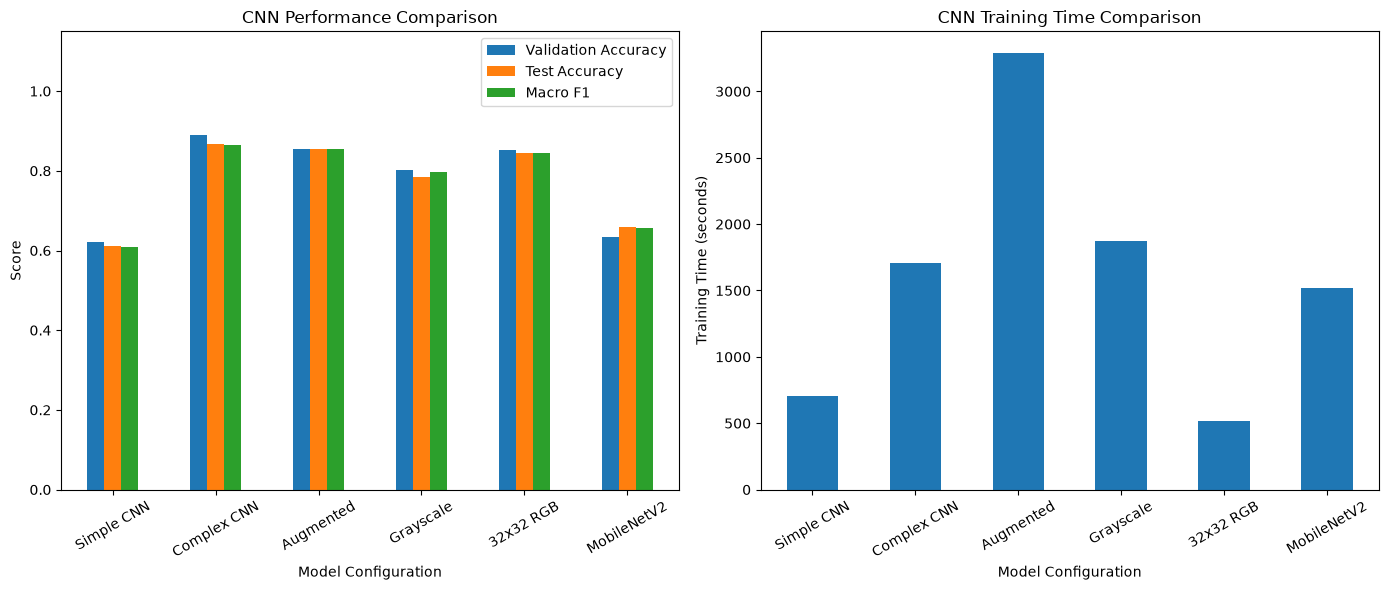

In [25]:
%matplotlib inline

full_comparison = comparison[comparison["num_classes"] == 29].copy()

full_comparison["configuration"] = [
    "Simple CNN",
    "Complex CNN",
    "Augmented",
    "Grayscale",
    "32x32 RGB",
    "MobileNetV2"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

full_comparison.plot(
    x="configuration",
    y=["val_accuracy", "test_accuracy", "test_macro_f1"],
    kind="bar",
    ax=axes[0],
    rot=30
)

axes[0].set_title("CNN Performance Comparison")
axes[0].set_xlabel("Model Configuration")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.15)
axes[0].legend([
    "Validation Accuracy",
    "Test Accuracy",
    "Macro F1"
], loc="upper right")

full_comparison.plot(
    x="configuration",
    y="train_time_s",
    kind="bar",
    ax=axes[1],
    legend=False,
    rot=30
)

axes[1].set_title("CNN Training Time Comparison")
axes[1].set_xlabel("Model Configuration")
axes[1].set_ylabel("Training Time (seconds)")

plt.tight_layout()
plt.savefig(results_dir / "comparison.png", dpi=150)
plt.show()

### Inference speed comparison

Inference speed was measured on the CPU using 200 test images, with one image processed at a time. Mean, median, and 95th percentile inference times are reported in milliseconds per image.

In [26]:
import json

timing_rows = []

for run_id in comparison["run_id"]:
    with open(Path("results") / f"{run_id}_test.json") as f:
        result = json.load(f)

    timing = result["inference_ms_per_image"]

    timing_rows.append({
        "configuration": run_id.replace("experiment2_", ""),
        "parameters": result["settings"]["parameters"],
        "mean_ms": timing["mean"],
        "median_ms": timing["median"],
        "p95_ms": timing["p95"]
    })

timing_comparison = pd.DataFrame(timing_rows)

timing_comparison.round(4)

,configuration,parameters,mean_ms,median_ms,p95_ms
0,simple_cnn_rgb64,1628893,8.8087,7.9925,13.1535
1,complex_cnn_rgb64,114397,13.5386,13.0386,15.3780
2,complex_cnn_augmented,114397,17.4631,15.5271,31.3203
3,complex_cnn_grayscale,113821,12.7531,12.4021,14.5465
4,complex_cnn_rgb32,114397,11.7211,11.4301,14.0855
5,complex_cnn_10class,111946,12.1192,12.0061,13.2021
6,pretrained_cnn_rgb64,2425693,106.7093,103.2936,121.7421


The simple CNN achieved the fastest mean inference time of 8.81 ms per image, but had considerably lower classification accuracy.

The complex CNN achieved a mean inference time of 13.54 ms per image while maintaining the highest test accuracy of 86.78%, providing a good balance between accuracy and inference speed.

The pretrained MobileNetV2 had the slowest mean inference time of 106.71 ms per image. The 32x32 RGB CNN achieved a mean inference time of 11.72 ms per image, demonstrating the computational benefits of reducing image resolution.

Although the complex CNN has more convolutional layers than the simple CNN, it contains fewer parameters because it uses global average pooling instead of flattening.

Inference times were measured on the same CPU and may vary depending on hardware and system workload.

### Results and observations

- **Simple vs. complex CNN:** The complex CNN achieved a test accuracy of 86.78%, compared to 61.22% for the simple CNN. The deeper architecture with batch normalization and dropout performed better on unseen images.

- **Custom vs. pretrained CNN:** The complex CNN outperformed the pretrained MobileNetV2 model, which achieved 65.87% test accuracy. The frozen pretrained features may not have been well suited to the ASL dataset at the selected image resolution.

- **Data augmentation:** Augmentation decreased test accuracy slightly from 86.78% to 85.51% while nearly doubling training time. Under the tested settings, augmentation did not improve classification performance.

- **Color vs. grayscale:** Removing color information decreased test accuracy from 86.78% to 78.50%, suggesting that color information is useful for ASL classification.

- **Image resolution:** Reducing the image size from 64x64 to 32x32 decreased test accuracy slightly to 84.55%, but reduced training time by approximately 69.7%.

- **Number of classes:** The 10-class CNN achieved 99.71% training accuracy but only 38.39% test accuracy, indicating significant overfitting. This configuration also used fewer training images and is therefore evaluated separately from the 29-class models.

The complex CNN with 64x64 RGB images and no augmentation was selected as the best CNN based on its validation accuracy of 88.89%. It achieved a test accuracy of 86.78% and a macro F1-score of 86.54%.

These results are based on a single training run per configuration and may vary with different training settings.

### Training and validation curves

The training curves show how each CNN learned over 10 epochs. Training and validation accuracy and loss are compared to identify overfitting and differences in learning behavior across configurations.

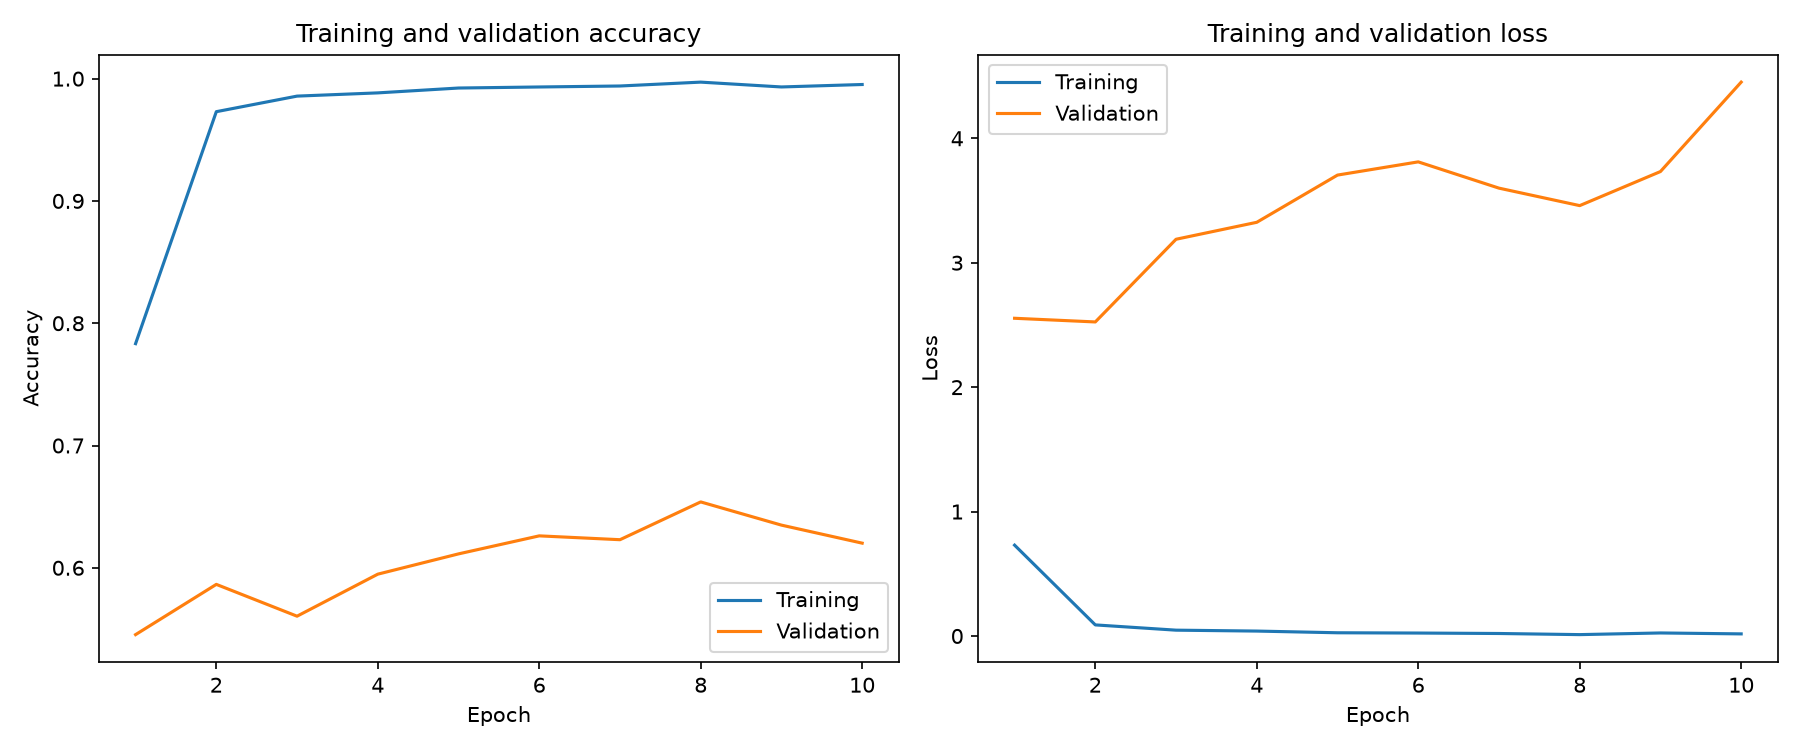

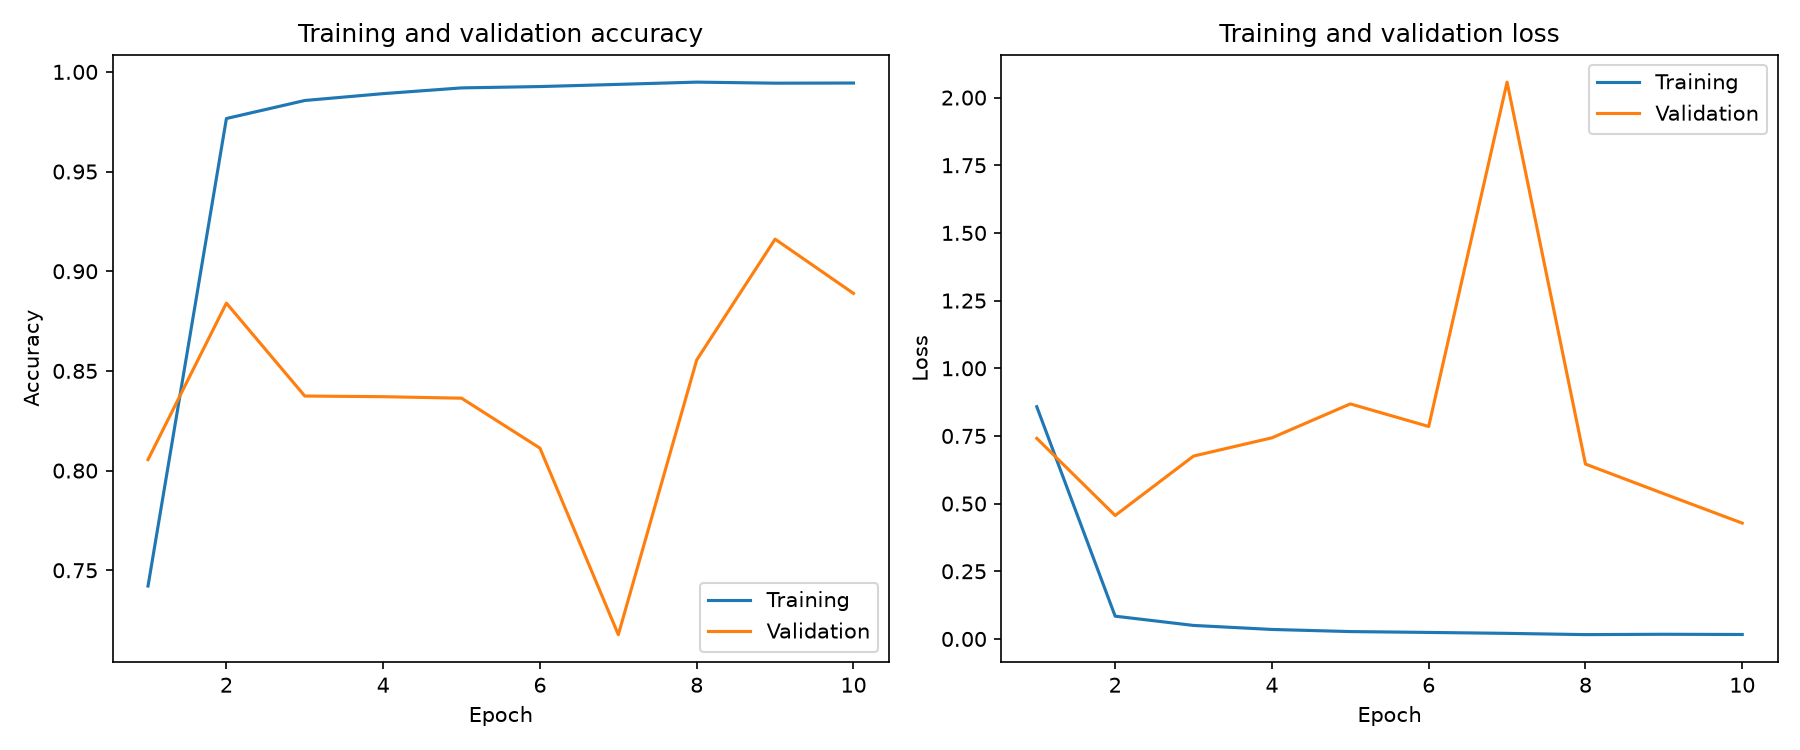

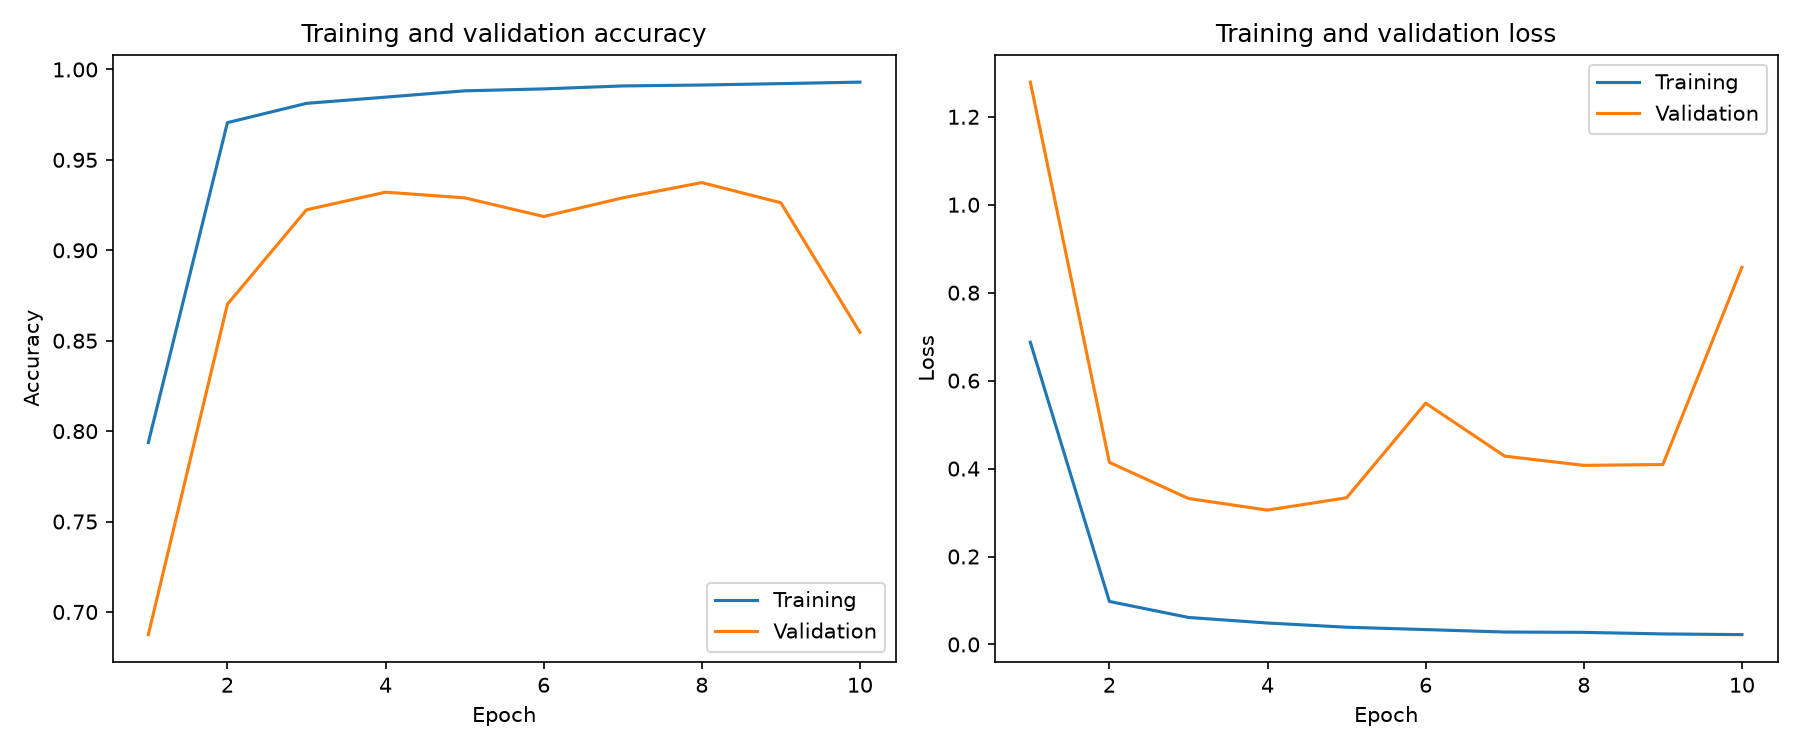

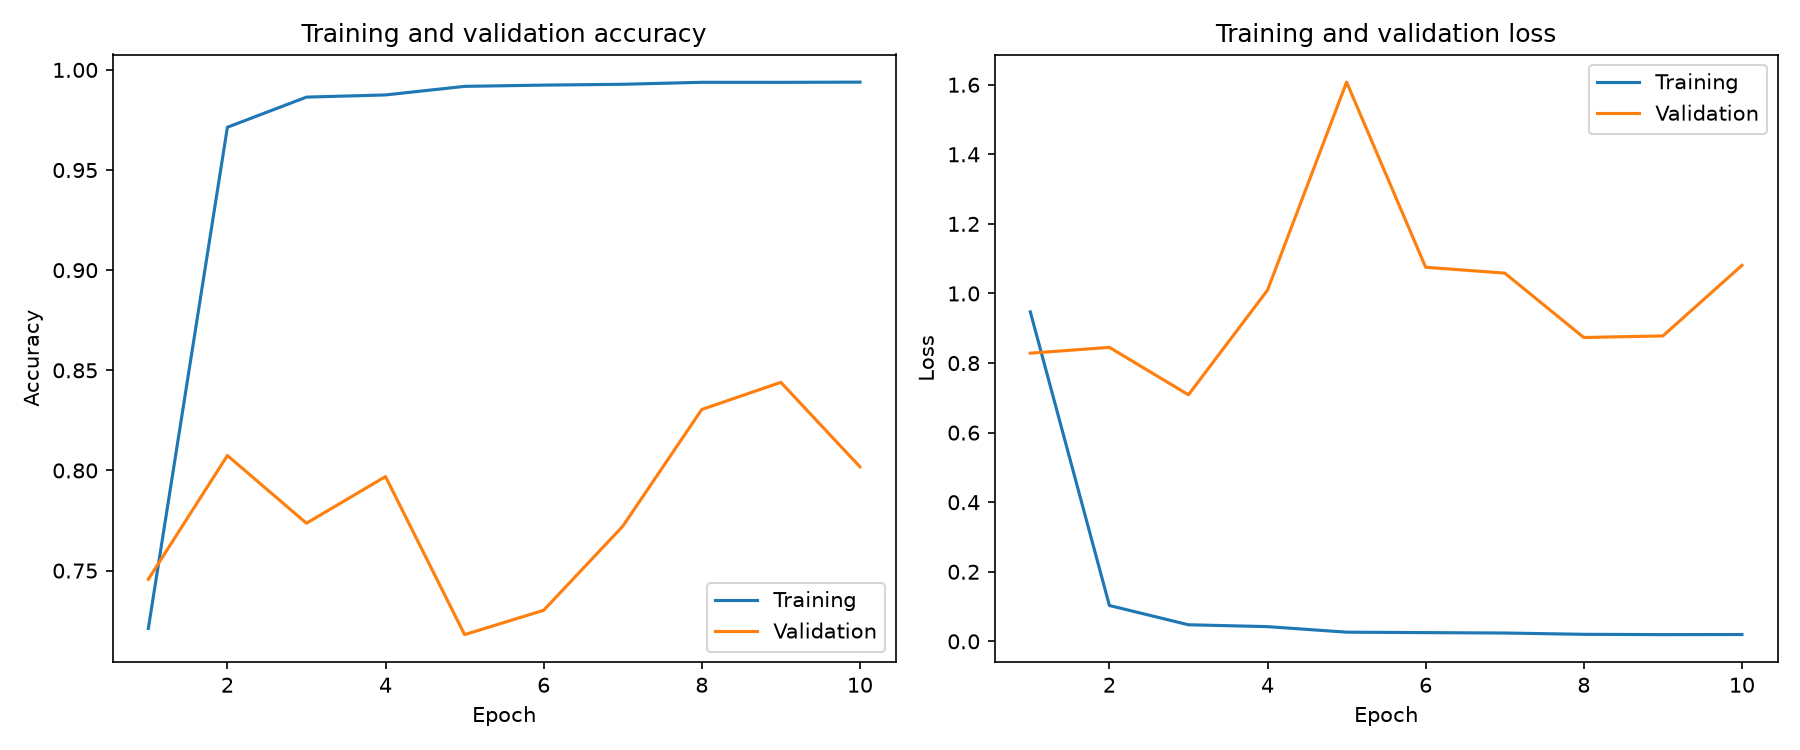

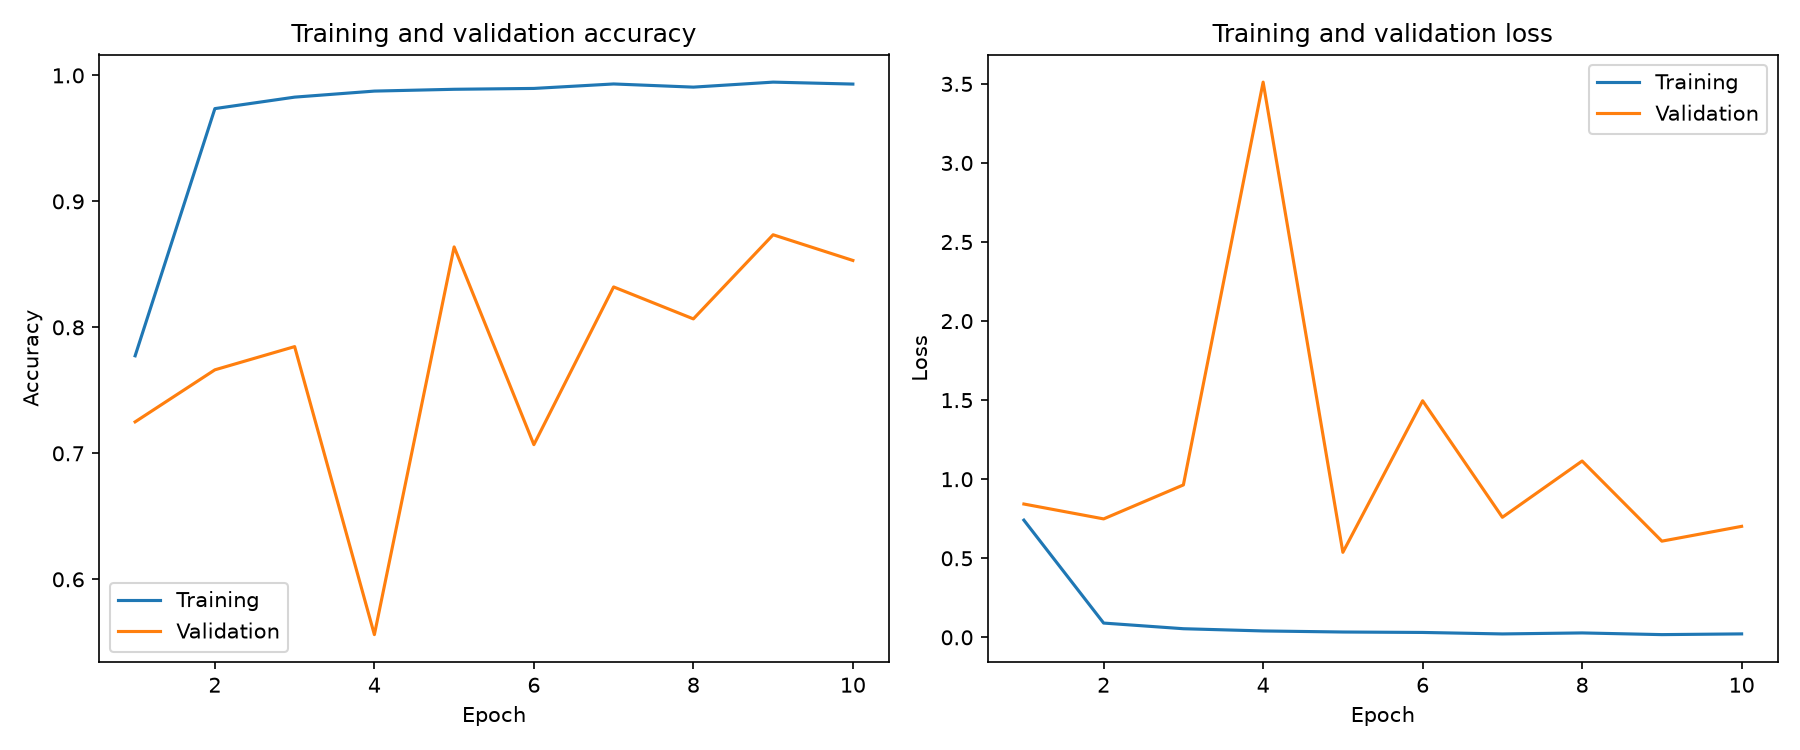

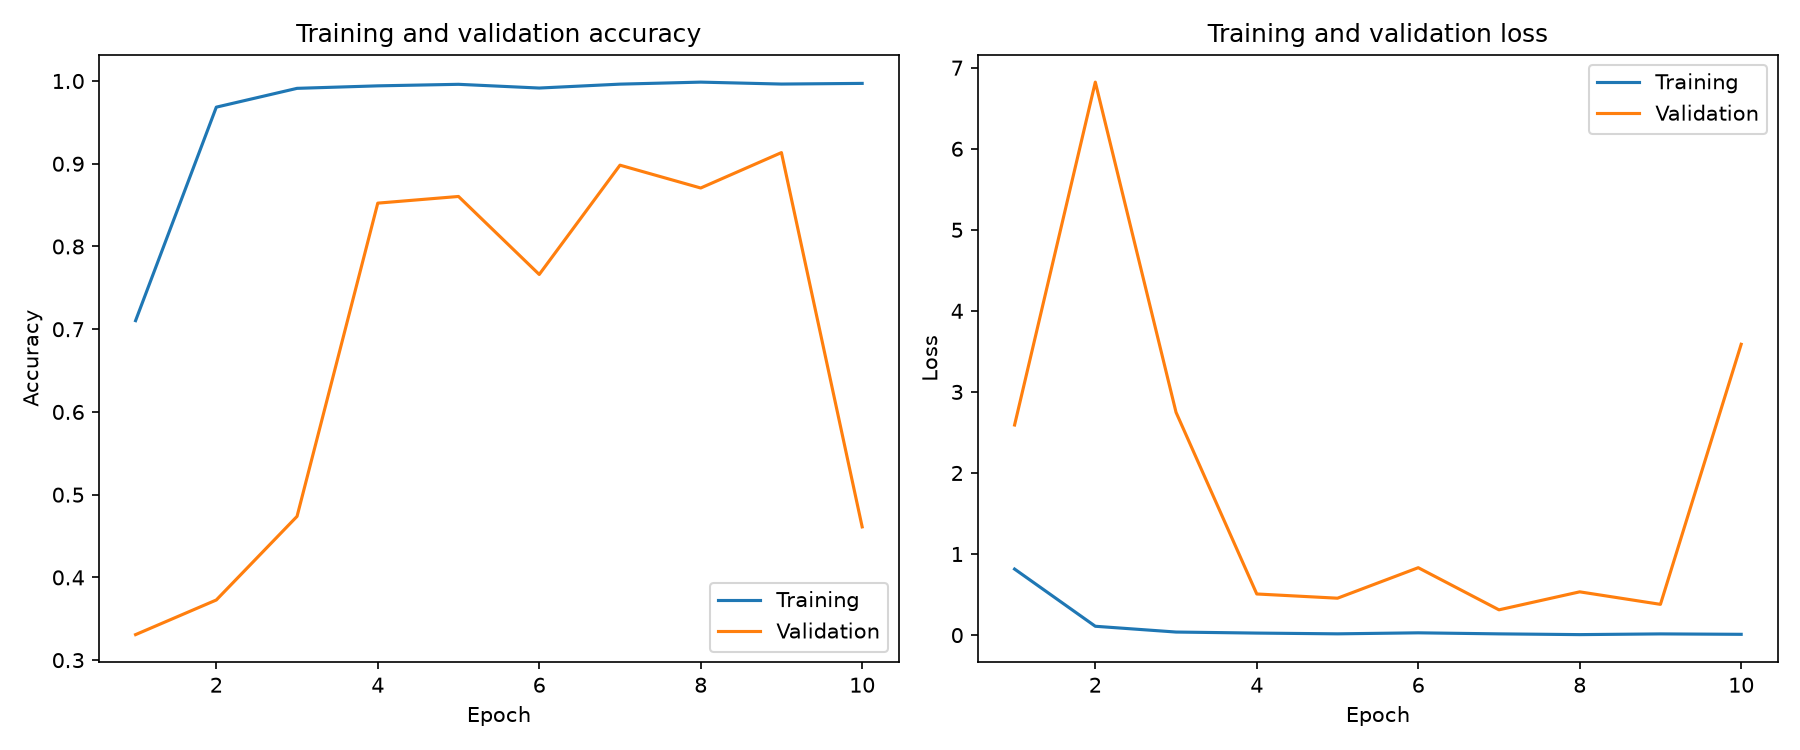

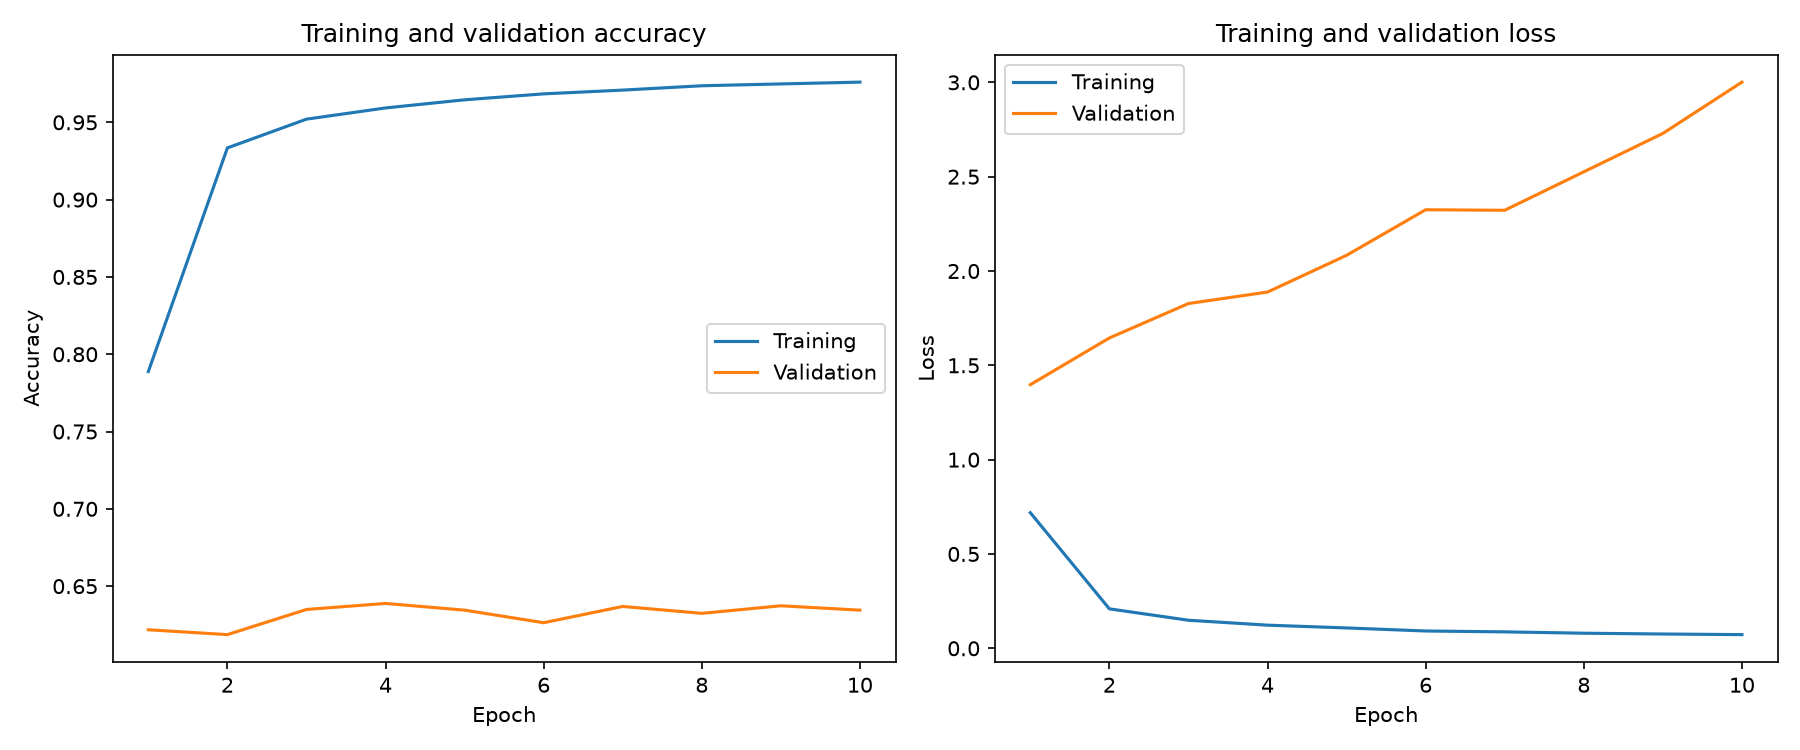

In [27]:
from IPython.display import Image, display

for run_id in comparison["run_id"]:
    display(Image(filename=str(
        results_dir / f"{run_id}_training_curves.png"
    )))

The training curves show that several CNN configurations achieved high training accuracy but lower validation accuracy, indicating overfitting.

The simple CNN and pretrained MobileNetV2 showed large gaps between training and validation accuracy. The complex CNN demonstrated better generalization and achieved the highest final validation accuracy among the 29-class models.

The 10-class CNN showed significant overfitting, reaching 99.71% training accuracy but only 46.11% validation accuracy.

## 3. Confusion analysis and limitations

Best CNN: experiment2_complex_cnn_rgb64
Validation accuracy: 0.8889
Test accuracy: 0.8678


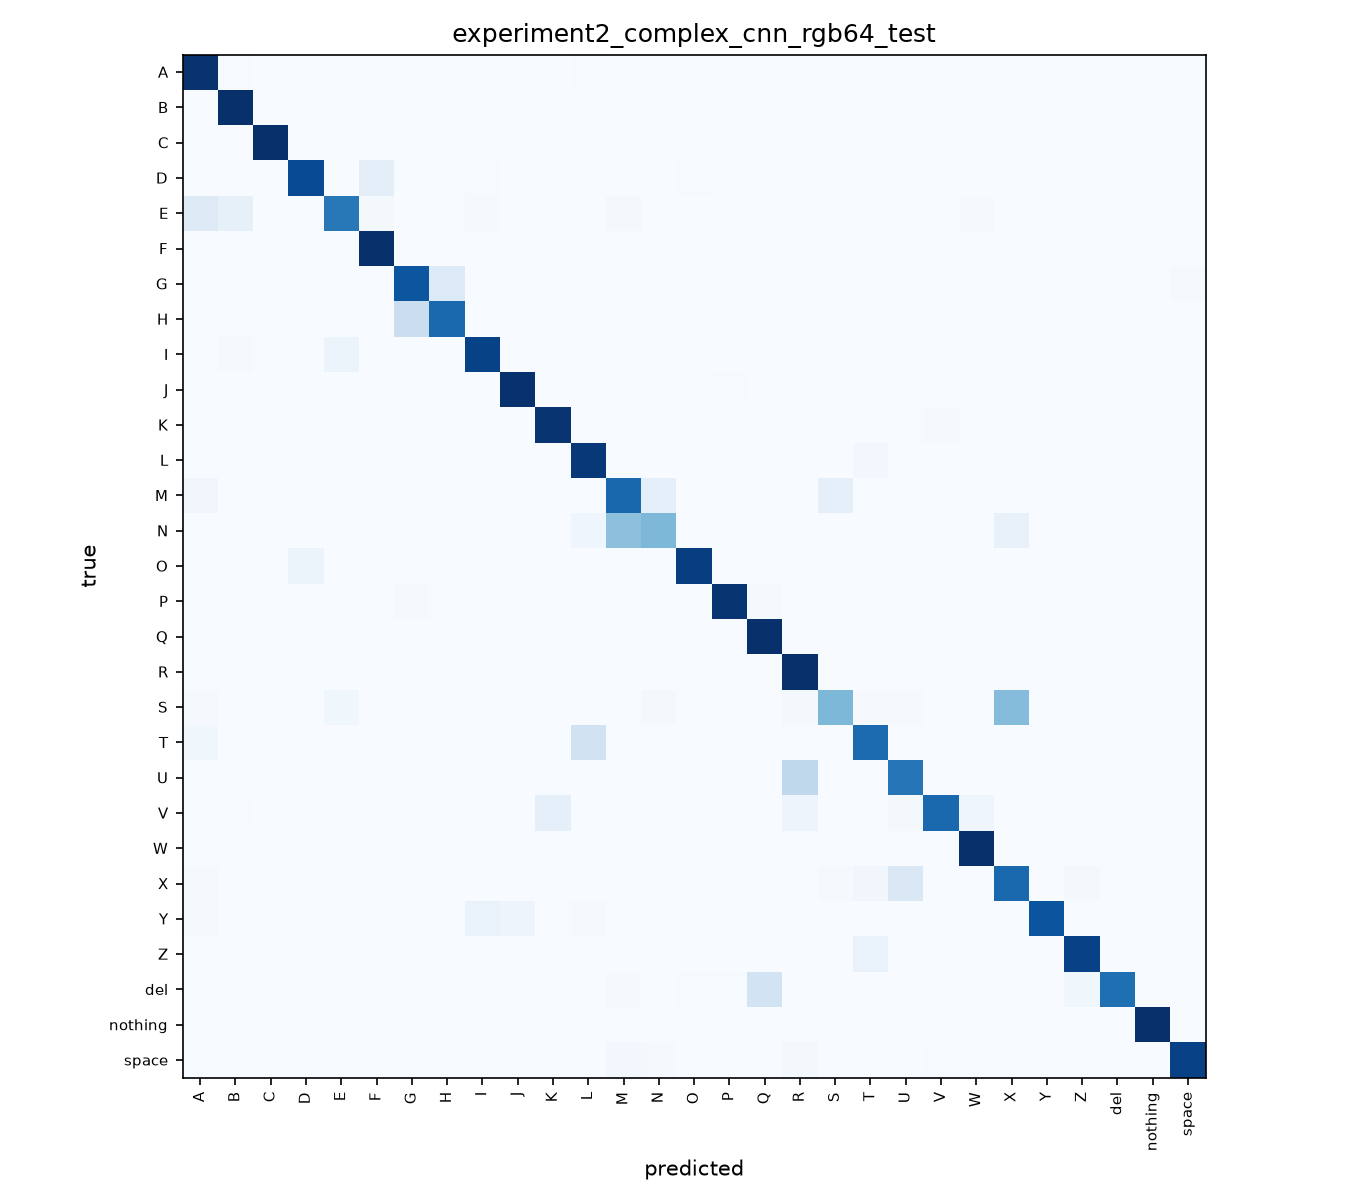

,true,predicted,count
0,S,X,152
1,N,M,125
2,U,R,81
3,H,G,66
4,del,Q,65
5,T,L,57
6,X,U,43
7,G,H,40
8,E,A,39
9,D,F,34


In [28]:
best_model = full_comparison.loc[
    full_comparison["val_accuracy"].idxmax()
]

best_run_id = best_model["run_id"]

print("Best CNN:", best_run_id)
print("Validation accuracy:", round(best_model["val_accuracy"], 4))
print("Test accuracy:", round(best_model["test_accuracy"], 4))

display(Image(filename=str(
    results_dir / f"{best_run_id}_confusion.png"
)))

pd.read_csv(
    results_dir / f"{best_run_id}_confusions.csv"
).head(10)

### Error analysis

The confusion matrix shows that the complex CNN correctly classified most test images, but struggled to distinguish certain hand signs. The most common misclassifications were S as X (152 images), N as M (125 images), U as R (81 images), and H as G (66 images).

Some of these errors may be explained by similarities in hand shapes and finger positions. For example, M and N have similar hand configurations with differences in finger placement, while G and H differ mainly in the number of extended fingers. These subtle differences can make classification difficult.

### Limitations

- The ASL Alphabet dataset contains limited variation in signers, backgrounds, and recording environments, which may limit generalization to real-world images.
- Resizing images may remove small visual details that are important for distinguishing similar hand signs.
- Several configurations showed overfitting, with high training accuracy but considerably lower validation accuracy.
- Each configuration was trained once for 10 epochs, so the results may vary with different random seeds, hyperparameters, or training durations.
- The pretrained MobileNetV2 model used frozen feature extraction layers without fine-tuning.

### Conclusion

The complex CNN trained on 64x64 RGB images without augmentation achieved the best overall performance among the tested 29-class CNN configurations, with 86.78% test accuracy and an 86.54% macro F1-score.

The 32x32 RGB CNN also demonstrated a useful trade-off between accuracy and computational cost, achieving 84.55% test accuracy with approximately 69.7% less training time.

Based on validation accuracy, the 64x64 RGB complex CNN was selected as the best CNN for potential integration into the webcam demonstration.